# Kathmandu AQI Prediction: Full Pipeline (v2)
**Module:** CSC61304 Machine Learning and Intelligent Systems | **Track:** ML for Air Quality Monitoring

**Goal:** predict `us_aqi` for Kathmandu from weather and time features.

**Pipeline order:** 1. Load data, 2. Data checks, 3. EDA, 4. Train/test split, 5. Feature engineering, 6. Feature selection, 7. Modeling, 8. Evaluation, 9. Save model.

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay)

## 1. Load data
Hourly Kathmandu weather + air quality data from Open-Meteo.

In [2]:
df = pd.read_csv("kathmandu_final.csv")

In [3]:
# Show all columns when printing tables
pd.set_option("display.max_columns", None)

### 1.1 First look: rows, shape, columns, types

In [4]:
df.head()

,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,shortwave_radiation,weather_code,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi
0,2022-08-05 05:00:00,20.3,98,20.0,23.6,4.2,4.2,868.7,100,4.2,110,11.2,1.0,63,31.7,22.2,478.0,14.1,5.2,68.0,0.31,0.0,0.05,63.0
1,2022-08-05 06:00:00,20.9,97,20.4,24.6,0.6,0.6,869.5,99,3.0,76,13.0,43.0,53,29.7,20.8,435.0,11.7,4.5,75.0,0.30,0.0,0.45,63.0
2,2022-08-05 07:00:00,21.8,93,20.6,25.4,0.1,0.1,870.0,89,4.2,59,12.2,147.0,51,25.3,17.7,374.0,8.2,3.6,85.0,0.25,0.0,1.65,64.0
3,2022-08-05 08:00:00,23.3,85,20.6,26.9,0.0,0.0,870.1,93,4.0,85,14.0,334.0,3,23.1,16.2,303.0,4.4,2.5,97.0,0.22,0.0,3.80,65.0
4,2022-08-05 09:00:00,25.4,76,20.8,29.4,0.0,0.0,869.9,100,2.6,124,14.8,565.0,3,20.3,14.2,272.0,2.9,2.1,103.0,0.21,0.0,6.15,65.0


In [5]:
df.tail()

,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,shortwave_radiation,weather_code,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi
36422,2026-09-30 19:00:00,20.8,95,20.0,24.2,0.0,0.0,873.0,12,3.4,328,7.2,0.0,0,35.7,34.2,1729.0,14.5,7.3,96.0,0.49,3.0,0.0,76.0
36423,2026-09-30 20:00:00,20.6,96,20.0,24.1,0.0,0.0,873.7,13,2.6,335,6.8,0.0,0,36.9,35.4,2102.0,16.1,8.3,95.0,0.51,3.0,0.0,77.0
36424,2026-09-30 21:00:00,20.7,95,20.0,24.4,0.0,0.0,874.2,13,1.2,51,5.0,0.0,0,35.0,33.5,2419.0,15.6,8.8,97.0,0.48,3.0,0.0,78.0
36425,2026-09-30 22:00:00,20.4,97,19.9,24.0,0.0,0.0,874.0,7,1.2,51,3.6,0.0,0,36.9,35.4,2673.0,14.0,9.0,100.0,0.47,3.0,0.0,78.0
36426,2026-09-30 23:00:00,20.1,98,19.9,23.5,0.0,0.0,873.4,5,3.1,13,3.2,0.0,0,36.4,34.9,2710.0,12.5,9.1,100.0,0.46,3.0,0.0,79.0


In [6]:
df.shape

(36427, 24)

In [7]:
df.columns

Index(['time', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m',
       'apparent_temperature', 'precipitation', 'rain', 'surface_pressure',
       'cloud_cover', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m',
       'shortwave_radiation', 'weather_code', 'pm10', 'pm2_5',
       'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone',
       'aerosol_optical_depth', 'dust', 'uv_index', 'us_aqi'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36427 entries, 0 to 36426
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   time                   36427 non-null  str    
 1   temperature_2m         36427 non-null  float64
 2   relative_humidity_2m   36427 non-null  int64  
 3   dew_point_2m           36427 non-null  float64
 4   apparent_temperature   36427 non-null  float64
 5   precipitation          36427 non-null  float64
 6   rain                   36427 non-null  float64
 7   surface_pressure       36427 non-null  float64
 8   cloud_cover            36427 non-null  int64  
 9   wind_speed_10m         36427 non-null  float64
 10  wind_direction_10m     36427 non-null  int64  
 11  wind_gusts_10m         36427 non-null  float64
 12  shortwave_radiation    36427 non-null  float64
 13  weather_code           36427 non-null  int64  
 14  pm10                   36427 non-null  float64
 15  pm2_5        

### 1.2 Summary statistics

In [9]:
df.describe()

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,shortwave_radiation,weather_code,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi
count,36427.000000,36427.00000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000
mean,18.284108,76.93708,13.520718,19.351234,0.283567,0.283567,870.427688,50.064046,4.344582,199.950559,14.274206,197.441952,14.922365,48.013605,36.216565,726.897384,14.507758,7.161762,97.175694,0.431932,10.494359,1.343501,104.184451
std,5.671127,20.15941,6.444381,7.466690,1.134090,1.134090,3.222026,42.094426,2.699231,79.412659,6.927304,264.498822,23.368451,30.095844,24.718793,488.240621,13.021203,5.220817,36.750611,0.261678,22.920121,2.216136,36.383301
min,0.800000,9.00000,-6.700000,-1.900000,0.000000,0.000000,860.000000,0.000000,0.000000,2.000000,1.400000,0.000000,0.000000,0.300000,0.200000,59.000000,0.000000,0.000000,6.000000,0.010000,0.000000,0.000000,12.000000
25%,14.300000,64.00000,8.000000,13.700000,0.000000,0.000000,868.200000,3.000000,2.400000,150.000000,9.400000,0.000000,0.000000,25.400000,18.600000,371.000000,3.700000,3.700000,68.000000,0.250000,0.000000,0.000000,74.000000
50%,19.300000,81.00000,14.000000,20.500000,0.000000,0.000000,870.300000,45.000000,3.800000,180.000000,13.000000,9.000000,2.000000,41.000000,29.900000,576.000000,11.300000,5.800000,95.000000,0.370000,1.000000,0.000000,95.000000
75%,22.300000,95.00000,19.900000,25.400000,0.100000,0.100000,872.600000,99.000000,5.600000,280.000000,17.600000,394.500000,51.000000,64.700000,46.300000,925.000000,21.900000,8.700000,124.000000,0.550000,7.000000,2.000000,135.000000
max,31.700000,100.00000,23.500000,36.900000,28.600000,28.600000,881.000000,100.000000,21.100000,360.000000,54.700000,981.000000,65.000000,221.200000,178.800000,3490.000000,107.400000,38.000000,233.000000,2.680000,250.000000,11.650000,217.000000


## 2. Data checks

### 2.1 Date range and duplicate timestamps

In [10]:
print("Start:", df["time"].min())
print("End  :", df["time"].max())

Start: 2022-08-05 05:00:00
End  : 2026-09-30 23:00:00


In [11]:
df["time"].duplicated().sum()

np.int64(0)

### 2.2 Column summary table (type, missing values, unique values)

In [12]:
infos = []
for col in df.columns:
    row = []
    row.append(col)
    row.append(str(df[col].dtype))
    row.append(df[col].isnull().sum())
    row.append(df[col].nunique())
    infos.append(row)

coumn_info = pd.DataFrame(infos, columns=['column','dtype','missing','unique'])
print(coumn_info)

                   column    dtype  missing  unique
0                    time      str        0   36427
1          temperature_2m  float64        0     306
2    relative_humidity_2m    int64        0      91
3            dew_point_2m  float64        0     298
4    apparent_temperature  float64        0     377
5           precipitation  float64        0     156
6                    rain  float64        0     156
7        surface_pressure  float64        0     207
8             cloud_cover    int64        0     101
9          wind_speed_10m  float64        0     187
10     wind_direction_10m    int64        0     358
11         wind_gusts_10m  float64        0     135
12    shortwave_radiation  float64        0     951
13           weather_code    int64        0      10
14                   pm10  float64        0     948
15                  pm2_5  float64        0     893
16        carbon_monoxide  float64        0    2414
17       nitrogen_dioxide  float64        0     768
18        su

In [13]:
coumn_info.to_csv("column_dtype_missing_unique_value.csv", index = False)

### 2.3 Convert `time` from text to datetime

In [14]:
df["time"] = pd.to_datetime(df["time"])

In [15]:
df["time"].dtype

dtype('<M8[us]')

## 3. Exploratory Data Analysis (EDA)

### 3.1 Distribution of the target (`us_aqi`)

<Axes: >

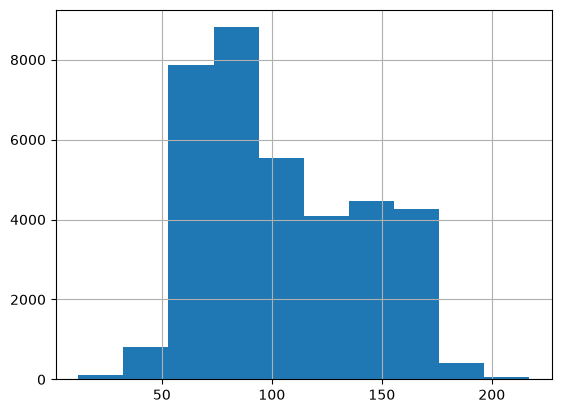

In [16]:
df["us_aqi"].hist()

### 3.2 AQI by hour of day

In [17]:
df["hour"] = df["time"].dt.hour

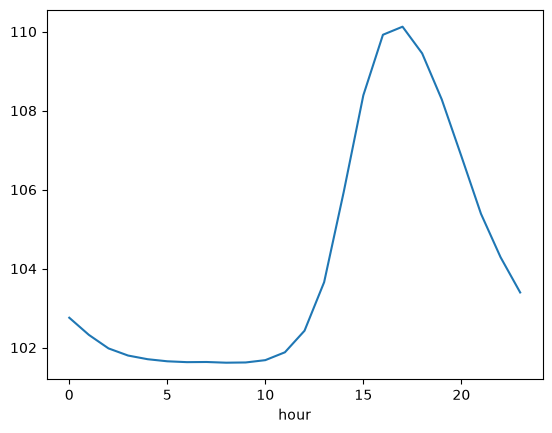

In [18]:
df.groupby("hour")["us_aqi"].mean().plot()
plt.show()

### 3.3 AQI by month (seasonal pattern)

In [19]:
df["month"] = df["time"].dt.month

<Axes: xlabel='month'>

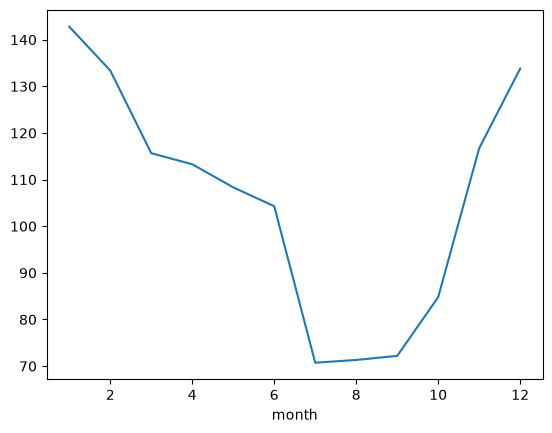

In [20]:
df.groupby("month")["us_aqi"].mean().plot()

### 3.4 Number of hours in each AQI category

In [1]:
pd.cut(df["us_aqi"], bins =[0, 50, 100, 150, 200, 300, 500]).value_counts()

NameError: name 'pd' is not defined

### 3.5 Correlation with `us_aqi`

In [22]:
df.corr()['us_aqi'].sort_values()

dew_point_2m            -0.539782
apparent_temperature    -0.495870
temperature_2m          -0.420693
cloud_cover             -0.370203
weather_code            -0.326138
month                   -0.279714
relative_humidity_2m    -0.252539
rain                    -0.196388
precipitation           -0.196388
uv_index                -0.078056
shortwave_radiation     -0.031445
hour                     0.053771
wind_direction_10m       0.064849
wind_gusts_10m           0.090207
wind_speed_10m           0.102072
time                     0.172280
nitrogen_dioxide         0.178548
surface_pressure         0.216781
dust                     0.294894
ozone                    0.322454
carbon_monoxide          0.392728
aerosol_optical_depth    0.393457
sulphur_dioxide          0.574293
pm10                     0.719540
pm2_5                    0.730693
us_aqi                   1.000000
Name: us_aqi, dtype: float64

### 3.6 Correlation heatmap (all features)

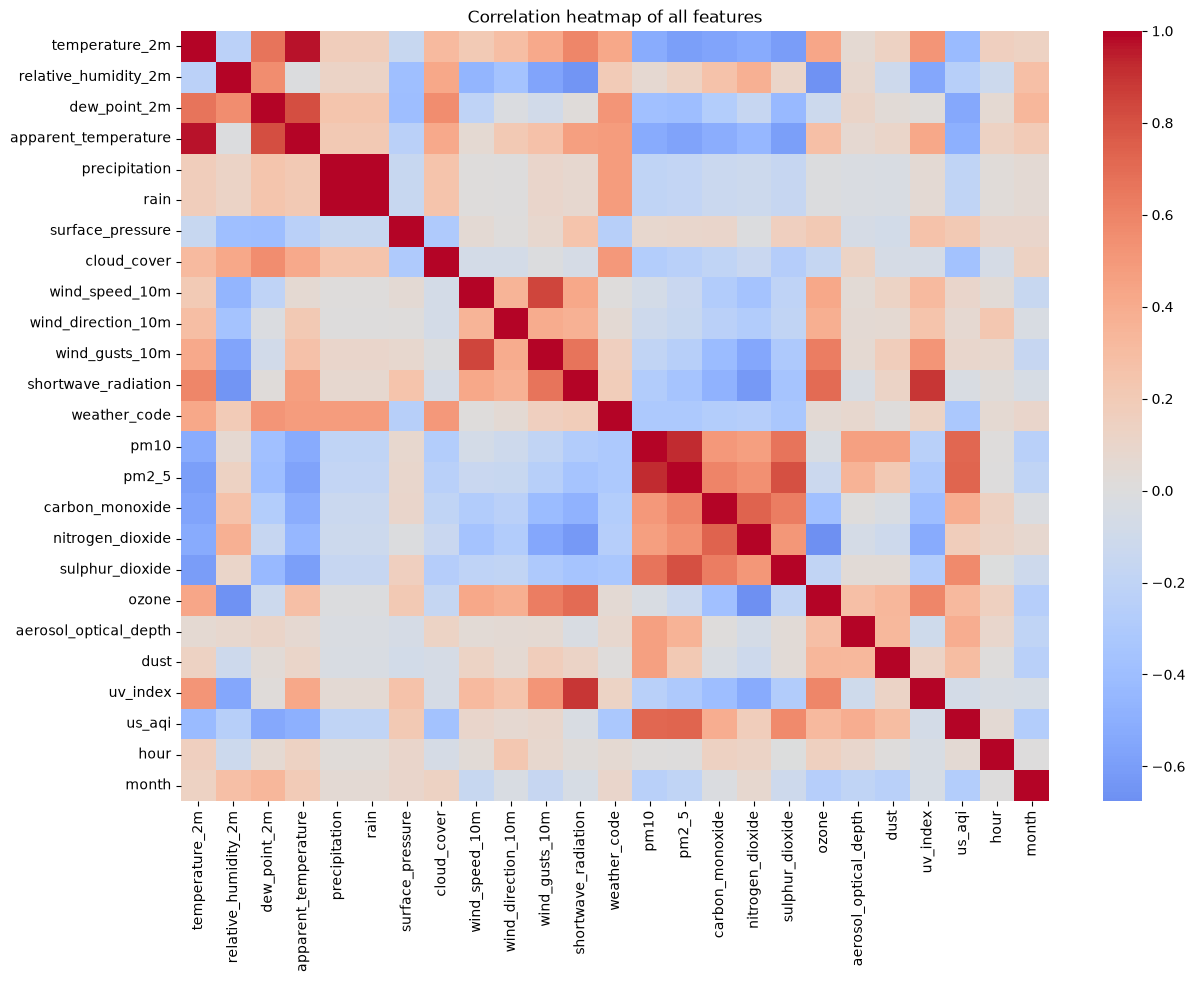

In [23]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.drop(columns="time").corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap of all features")
plt.show()

## 4. Train / test split (time-based)
Train on the past, test on the future, so the model never sees future data.
- **Train:** Oct 2022 to Sep 2025 - 3 years
- **Test:** Oct 2025 to Sep 2026 - 1 year

In [24]:
# Training data: October 2022 – September 2025
train_df = df[
    (df['time'] >= '2022-10-01') &
    (df['time'] < '2025-10-01')
].copy()

# Testing data: October 2025 – September 2026
test_df = df[
    (df['time'] >= '2025-10-01') &
    (df['time'] < '2026-10-01')
].copy()

In [25]:
train_df.tail()

,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,shortwave_radiation,weather_code,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,hour,month
27662,2025-09-30 19:00:00,20.4,96,19.8,23.8,0.0,0.0,867.9,44,3.0,163,10.1,0.0,1,33.4,33.2,2102.0,24.0,7.0,67.0,0.34,0.0,0.0,81.0,19,9
27663,2025-09-30 20:00:00,19.5,100,19.5,22.6,0.0,0.0,868.7,100,3.6,162,10.8,0.0,3,34.6,34.3,2510.0,29.0,8.3,58.0,0.34,0.0,0.0,80.0,20,9
27664,2025-09-30 21:00:00,18.9,100,18.9,21.9,0.0,0.0,868.7,100,3.0,163,10.8,0.0,3,36.8,36.4,2527.0,32.0,9.1,52.0,0.36,0.0,0.0,80.0,21,9
27665,2025-09-30 22:00:00,18.8,100,18.8,21.5,0.0,0.0,868.8,100,3.9,164,11.5,0.0,3,40.0,39.8,2318.0,33.8,9.5,47.0,0.38,0.0,0.0,79.0,22,9
27666,2025-09-30 23:00:00,18.5,100,18.5,21.3,0.0,0.0,868.5,100,2.4,171,12.2,0.0,3,40.7,40.5,2045.0,34.4,9.7,44.0,0.36,0.0,0.0,80.0,23,9


In [26]:
test_df.tail()

,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,shortwave_radiation,weather_code,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,hour,month
36422,2026-09-30 19:00:00,20.8,95,20.0,24.2,0.0,0.0,873.0,12,3.4,328,7.2,0.0,0,35.7,34.2,1729.0,14.5,7.3,96.0,0.49,3.0,0.0,76.0,19,9
36423,2026-09-30 20:00:00,20.6,96,20.0,24.1,0.0,0.0,873.7,13,2.6,335,6.8,0.0,0,36.9,35.4,2102.0,16.1,8.3,95.0,0.51,3.0,0.0,77.0,20,9
36424,2026-09-30 21:00:00,20.7,95,20.0,24.4,0.0,0.0,874.2,13,1.2,51,5.0,0.0,0,35.0,33.5,2419.0,15.6,8.8,97.0,0.48,3.0,0.0,78.0,21,9
36425,2026-09-30 22:00:00,20.4,97,19.9,24.0,0.0,0.0,874.0,7,1.2,51,3.6,0.0,0,36.9,35.4,2673.0,14.0,9.0,100.0,0.47,3.0,0.0,78.0,22,9
36426,2026-09-30 23:00:00,20.1,98,19.9,23.5,0.0,0.0,873.4,5,3.1,13,3.2,0.0,0,36.4,34.9,2710.0,12.5,9.1,100.0,0.46,3.0,0.0,79.0,23,9


## 5. Feature engineering: cyclic encoding of hour and month
Hour 23 and hour 0 are neighbours in real life, and so are month 12 and month 1. Sine and cosine put them on a circle so the model sees that. Both are needed because sine alone repeats (hour 0 and hour 12 both give 0).

In [27]:
# Apply cyclic encoding to training data
train_df['hour_sin'] = np.sin(2 * np.pi * train_df['hour'] / 24)
train_df['hour_cos'] = np.cos(2 * np.pi * train_df['hour'] / 24)

train_df['month_sin'] = np.sin(2 * np.pi * train_df['month'] / 12)
train_df['month_cos'] = np.cos(2 * np.pi * train_df['month'] / 12)


# Apply cyclic encoding to testing data
test_df['hour_sin'] = np.sin(2 * np.pi * test_df['hour'] / 24)
test_df['hour_cos'] = np.cos(2 * np.pi * test_df['hour'] / 24)

test_df['month_sin'] = np.sin(2 * np.pi * test_df['month'] / 12)
test_df['month_cos'] = np.cos(2 * np.pi * test_df['month'] / 12)

In [28]:
print("Training Data:")
print(train_df[['hour', 'month', 'hour_sin', 'hour_cos',
                'month_sin', 'month_cos']].head())

print("\nTesting Data:")
print(test_df[['hour', 'month', 'hour_sin', 'hour_cos',
               'month_sin', 'month_cos']].head())

Training Data:
      hour  month  hour_sin  hour_cos  month_sin  month_cos
1363     0     10  0.000000  1.000000  -0.866025        0.5
1364     1     10  0.258819  0.965926  -0.866025        0.5
1365     2     10  0.500000  0.866025  -0.866025        0.5
1366     3     10  0.707107  0.707107  -0.866025        0.5
1367     4     10  0.866025  0.500000  -0.866025        0.5

Testing Data:
       hour  month  hour_sin  hour_cos  month_sin  month_cos
27667     0     10  0.000000  1.000000  -0.866025        0.5
27668     1     10  0.258819  0.965926  -0.866025        0.5
27669     2     10  0.500000  0.866025  -0.866025        0.5
27670     3     10  0.707107  0.707107  -0.866025        0.5
27671     4     10  0.866025  0.500000  -0.866025        0.5


## 6. Feature selection
Weather and time features only. PM2.5 and PM10 are left out on purpose because US AQI is calculated from them, which would leak the answer into the inputs.

The sin/cos columns replace the raw `hour` and `month`.

In [29]:
features = ["temperature_2m", "dew_point_2m", "cloud_cover", "weather_code",
            "precipitation", "hour_sin", "hour_cos", "month_sin", "month_cos"]
target = "us_aqi"

df_weather_train = train_df[["time"] + features + [target]]
df_weather_test  = test_df[["time"] + features + [target]]

df_weather_train.columns

Index(['time', 'temperature_2m', 'dew_point_2m', 'cloud_cover', 'weather_code',
       'precipitation', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
       'us_aqi'],
      dtype='str')

In [30]:
df_weather_train.to_csv("kathmandu_weather_train.csv", index = False)
df_weather_test.to_csv("kathmandu_weather_test.csv", index = False)

## 7. Modeling: Random Forest Regressor
Inputs (`X`) are the selected features and the output (`y`) is `us_aqi`.

In [31]:
X_train, y_train = train_df[features], train_df[target]
X_test,  y_test  = test_df[features],  test_df[target]

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (26304, 9)  Test: (8760, 9)


In [32]:
model = RandomForestRegressor(n_estimators=200, random_state=12, n_jobs=-1)
model.fit(X_train, y_train)

pred = model.predict(X_test)

## 8. Evaluation

### 8.1 Regression metrics
- **MAE:** average error in AQI points
- **RMSE:** like MAE but penalises big misses more
- **R²:** share of AQI variation the model explains (1.0 is perfect)

In [33]:
base_mae  = mean_absolute_error(y_test, pred)
base_rmse = np.sqrt(mean_squared_error(y_test, pred))
base_r2   = r2_score(y_test, pred)

print(f"MAE : {base_mae:.2f}")
print(f"RMSE: {base_rmse:.2f}")
print(f"R2  : {base_r2:.3f}")

MAE : 21.43
RMSE: 27.53
R2  : 0.467


# Hyperparameter Tuning

In [34]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, 30, None],
    "min_samples_leaf": [1, 5, 10],
    "max_features": ["sqrt", 0.5, 1.0]
}

tscv = TimeSeriesSplit(n_splits=3)

search = RandomizedSearchCV(
    RandomForestRegressor(random_state=12, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    random_state=12,
)

search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print(f"Best CV MAE: {-search.best_score_:.2f}")

best_model = search.best_estimator_

Best settings: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 10}
Best CV MAE: 25.62


In [35]:
results = pd.DataFrame(search.cv_results_)
results = results[["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
                   "param_max_features", "mean_test_score"]]
results["cv_mae"] = -results["mean_test_score"]
results = results.sort_values("cv_mae").drop(columns="mean_test_score")
results.to_csv("rf_tuning_results.csv", index=False)
results.head(10)

,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,cv_mae
10,200,10,10,sqrt,25.616207
7,100,30,10,sqrt,25.730197
13,300,10,10,0.5,25.769143
5,300,10,5,0.5,25.792874
12,200,20,5,sqrt,25.874229
3,300,None,10,0.5,25.881637
14,200,None,10,0.5,25.885106
11,200,20,5,0.5,26.009603
4,100,20,5,0.5,26.014300
8,300,10,10,1.0,26.101806


In [36]:
tuned_pred = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Random Forest (baseline)", "Random Forest (tuned)"],
    "MAE":  [base_mae,  mean_absolute_error(y_test, tuned_pred)],
    "RMSE": [base_rmse, np.sqrt(mean_squared_error(y_test, tuned_pred))],
    "R2":   [base_r2,   r2_score(y_test, tuned_pred)],
}).round(3)
comparison

,Model,MAE,RMSE,R2
0,Random Forest (baseline),21.428,27.527,0.467
1,Random Forest (tuned),20.444,25.717,0.535


### 8.2 Confusion matrix (AQI categories)
A confusion matrix needs classes, so both the real and the predicted AQI are grouped into AQI categories, then compared.

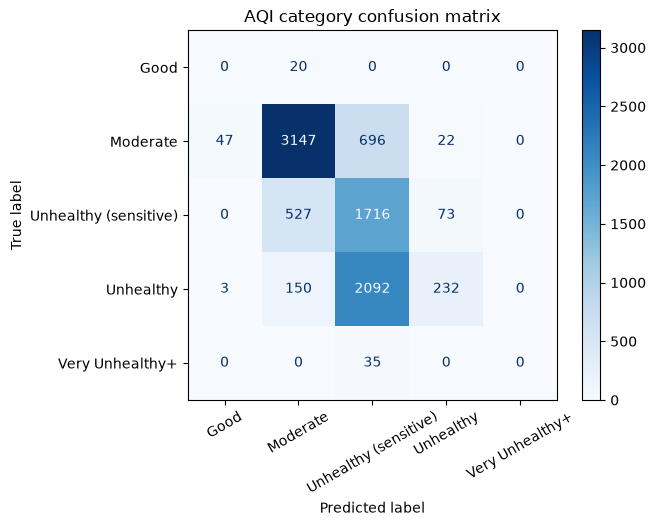

In [37]:
bins   = [-1, 50, 100, 150, 200, 500]
labels = ["Good", "Moderate", "Unhealthy (sensitive)", "Unhealthy", "Very Unhealthy+"]

y_test_cat = pd.cut(y_test, bins=bins, labels=labels)
pred_cat   = pd.cut(pred,   bins=bins, labels=labels)

cm = confusion_matrix(y_test_cat, pred_cat, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", xticks_rotation=30)
plt.title("AQI category confusion matrix")
plt.show()

## 9. Save the model (deployment step)
Save the trained model to a file, load it back, and predict with the loaded copy to prove it works.

In [40]:
joblib.dump(best_model, "rf_aqi_model.pkl")



['rf_aqi_model.pkl']

In [47]:
loaded_model = joblib.load("rf_aqi_model.pkl")
print(loaded_model.predict(X_test.sample(10)))

[118.36961087  73.71325756 120.44624794 111.51411791  65.66015053
 130.58358033  66.45374887  87.33011136  72.68398775 101.94481075]


In [52]:
print(loaded_model.predict(X_test.iloc[[100]]), y_test.iloc[[100]])

[83.8221987] 27767    65.0
Name: us_aqi, dtype: float64


count    8760.000000
mean       21.427654
std        17.281245
min         0.000000
25%         7.975937
50%        16.997500
75%        31.068759
max       117.755000
Name: us_aqi, dtype: float64


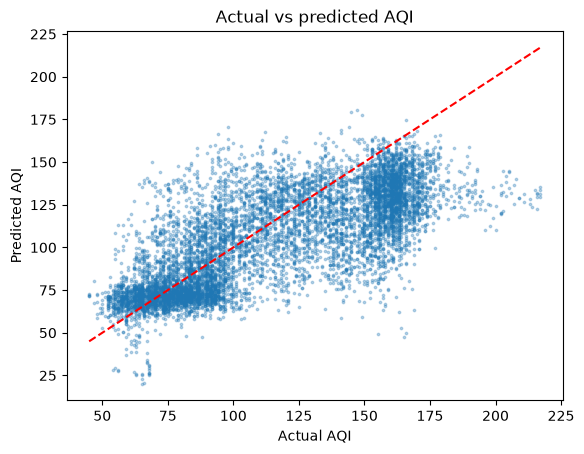

In [53]:
errors = (pred - y_test).abs()
print(errors.describe())          # typical error, worst error, spread

plt.scatter(y_test, pred, s=3, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual AQI"); plt.ylabel("Predicted AQI")
plt.title("Actual vs predicted AQI")
plt.show()